# Computer Vision Assignments: Sessions 1 & 2

This notebook contains tasks and assignments based on Sessions 1 and 2. You are required to implement the functions and complete the exercises as described. Use OpenCV and other necessary libraries like NumPy and Matplotlib.

**Instructions:**
- Complete each task in the provided code cells.
- Test your implementations with sample images (e.g., download test images [here](https://sipi.usc.edu/database/database.php?volume=misc) or [here](https://www.hlevkin.com/hlevkin/06testimages.htm) or use your own test images).
- Include comments in your code for clarity.
- Display results using cv2.imshow() or Matplotlib where appropriate.
- Submit the completed notebook along with any output images or explanations on [our google drive for the CV sessions](https://drive.google.com/drive/folders/1IjVhJmAXxNQTGT-ybJ-yc5smYtR5v8CO?usp=sharing) **upload your files in a new folder under your name**

## Session 1: Basic Image Operations (Reading, Resizing, Cropping, Rotating)

### Task 1: Read and Display an Image
Read an image from a file and display it in both BGR and grayscale formats. Handle errors if the image cannot be read.

Loaded image: shape=(160, 240, 3), dtype=uint8, OpenCV available=False
task01_read_display: tasks1_outputs\task01_read_display.png


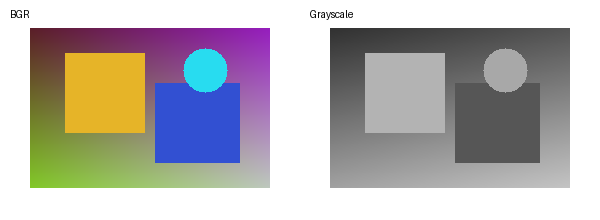

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
from PIL import Image, ImageDraw, ImageFilter

try:
    import cv2 as cv
    USING_OPENCV = True
except ImportError:
    USING_OPENCV = False


ARTIFACT_DIR = Path("tasks1_outputs")
ARTIFACT_DIR.mkdir(exist_ok=True)
displayed_paths = []


def _as_uint8(image):
    array = np.asarray(image)
    if array.dtype == np.uint8:
        return array
    array = np.nan_to_num(array.astype(np.float32))
    if array.max(initial=0) <= 1.0 and array.min(initial=0) >= 0.0:
        array = array * 255.0
    return np.clip(array, 0, 255).astype(np.uint8)


def _save_bgr(path, image):
    array = _as_uint8(image)
    if array.ndim == 2:
        Image.fromarray(array, mode="L").save(path)
    else:
        Image.fromarray(array[..., ::-1], mode="RGB").save(path)


def _make_sample_image(path, width=240, height=160):
    y, x = np.mgrid[0:height, 0:width]
    image = np.zeros((height, width, 3), dtype=np.uint8)
    image[..., 0] = (40 + 150 * x / max(width - 1, 1)).astype(np.uint8)
    image[..., 1] = (30 + 170 * y / max(height - 1, 1)).astype(np.uint8)
    image[..., 2] = (90 + 100 * (x + y) / max(width + height - 2, 1)).astype(np.uint8)
    image[25:105, 35:115] = (40, 180, 230)
    image[55:135, 125:210] = (210, 80, 50)
    yy, xx = np.ogrid[:height, :width]
    circle = (xx - 175) ** 2 + (yy - 42) ** 2 <= 22 ** 2
    image[circle] = (240, 220, 40)
    _save_bgr(path, image)


if not USING_OPENCV:
    class _OpenCVFallback:
        IMREAD_COLOR = 1
        IMREAD_GRAYSCALE = 0
        COLOR_BGR2GRAY = 6
        COLOR_BGR2RGB = 4
        COLOR_BGR2HSV = 40
        COLOR_BGR2LAB = 44
        INTER_NEAREST = 0
        INTER_LINEAR = 1
        INTER_AREA = 3

        @staticmethod
        def imread(path, flags=IMREAD_COLOR):
            try:
                rgb = np.asarray(Image.open(path).convert("RGB"))
            except (FileNotFoundError, OSError):
                return None
            bgr = rgb[..., ::-1].copy()
            if flags == _OpenCVFallback.IMREAD_GRAYSCALE:
                return _OpenCVFallback.cvtColor(bgr, _OpenCVFallback.COLOR_BGR2GRAY)
            return bgr

        @staticmethod
        def imwrite(path, image):
            _save_bgr(path, image)
            return True

        @staticmethod
        def cvtColor(image, code):
            image = _as_uint8(image)
            if code == _OpenCVFallback.COLOR_BGR2RGB:
                return image[..., ::-1].copy()
            if code == _OpenCVFallback.COLOR_BGR2GRAY:
                return np.rint(0.114 * image[..., 0] + 0.587 * image[..., 1] + 0.299 * image[..., 2]).astype(np.uint8)
            rgb = image[..., ::-1]
            pil = Image.fromarray(rgb, mode="RGB")
            if code == _OpenCVFallback.COLOR_BGR2HSV:
                return np.asarray(pil.convert("HSV"))
            if code == _OpenCVFallback.COLOR_BGR2LAB:
                return np.asarray(pil.convert("LAB"))
            raise ValueError(f"Unsupported color conversion code: {code}")

        @staticmethod
        def resize(image, dsize, fx=None, fy=None, interpolation=INTER_LINEAR):
            image = _as_uint8(image)
            if dsize is None or tuple(dsize) == (0, 0):
                dsize = (max(1, int(round(image.shape[1] * fx))), max(1, int(round(image.shape[0] * fy))))
            width, height = map(int, dsize)
            mode = "L" if image.ndim == 2 else "RGB"
            rgb = image if image.ndim == 2 else image[..., ::-1]
            pil = Image.fromarray(rgb, mode=mode)
            resample = Image.Resampling.NEAREST if interpolation == _OpenCVFallback.INTER_NEAREST else Image.Resampling.BILINEAR
            resized = np.asarray(pil.resize((width, height), resample=resample))
            return resized if image.ndim == 2 else resized[..., ::-1].copy()

        @staticmethod
        def getRotationMatrix2D(center, angle, scale):
            return {"angle": angle, "scale": scale}

        @staticmethod
        def warpAffine(image, matrix, dsize):
            image = _as_uint8(image)
            mode = "L" if image.ndim == 2 else "RGB"
            rgb = image if image.ndim == 2 else image[..., ::-1]
            rotated = Image.fromarray(rgb, mode=mode).rotate(matrix["angle"], resample=Image.Resampling.BILINEAR, expand=False)
            if matrix["scale"] != 1:
                rotated = rotated.resize((max(1, round(rotated.width * matrix["scale"])), max(1, round(rotated.height * matrix["scale"]))), Image.Resampling.BILINEAR)
                canvas = Image.new(mode, (image.shape[1], image.shape[0]))
                offset = ((canvas.width - rotated.width) // 2, (canvas.height - rotated.height) // 2)
                canvas.paste(rotated, offset)
                rotated = canvas
            result = np.asarray(rotated.resize(tuple(map(int, dsize)), Image.Resampling.BILINEAR))
            return result if image.ndim == 2 else result[..., ::-1].copy()

        @staticmethod
        def blur(image, ksize):
            image = _as_uint8(image)
            radius = max(1, int(max(ksize) // 2))
            mode = "L" if image.ndim == 2 else "RGB"
            rgb = image if image.ndim == 2 else image[..., ::-1]
            result = np.asarray(Image.fromarray(rgb, mode=mode).filter(ImageFilter.BoxBlur(radius)))
            return result if image.ndim == 2 else result[..., ::-1].copy()

        @staticmethod
        def filter2D(image, ddepth, kernel):
            image = _as_uint8(image)
            kernel = np.asarray(kernel, dtype=np.float32)
            radius_y, radius_x = kernel.shape[0] // 2, kernel.shape[1] // 2
            if image.ndim == 2:
                padded = np.pad(image.astype(np.float32), ((radius_y, radius_y), (radius_x, radius_x)), mode="reflect")
                windows = np.lib.stride_tricks.sliding_window_view(padded, kernel.shape)
                return np.clip((windows * kernel).sum(axis=(-2, -1)), 0, 255).astype(np.uint8)
            channels = [_OpenCVFallback.filter2D(image[..., c], ddepth, kernel) for c in range(image.shape[2])]
            return np.stack(channels, axis=-1)

        @staticmethod
        def medianBlur(image, ksize):
            image = _as_uint8(image)
            radius = ksize // 2
            if image.ndim == 2:
                padded = np.pad(image, ((radius, radius), (radius, radius)), mode="reflect")
                windows = np.lib.stride_tricks.sliding_window_view(padded, (ksize, ksize))
                return np.median(windows, axis=(-2, -1)).astype(np.uint8)
            channels = [_OpenCVFallback.medianBlur(image[..., c], ksize) for c in range(image.shape[2])]
            return np.stack(channels, axis=-1)

        @staticmethod
        def bilateralFilter(image, diameter, sigma_color, sigma_space):
            return custom_bilateral_filter(image, diameter, sigma_color, sigma_space)

        class VideoCapture:
            def __init__(self, source):
                self.source = source
            def isOpened(self):
                return False
            def read(self):
                return False, None
            def release(self):
                pass

        @staticmethod
        def waitKey(delay):
            return -1

        @staticmethod
        def destroyWindow(name):
            pass

    cv = _OpenCVFallback()


def _prepare_display(image, mode="bgr"):
    array = _as_uint8(image)
    if array.ndim == 2:
        return Image.fromarray(array, mode="L").convert("RGB")
    if mode == "bgr":
        array = array[..., ::-1]
    return Image.fromarray(array[..., :3], mode="RGB")


def show_images(items, title, cols=3):
    prepared = []
    for item in items:
        label, image = item[:2]
        mode = item[2] if len(item) > 2 else "bgr"
        prepared.append((str(label), _prepare_display(image, mode)))
    tile_w, tile_h = 300, 220
    rows = (len(prepared) + cols - 1) // cols
    canvas = Image.new("RGB", (cols * tile_w, rows * tile_h), "white")
    draw = ImageDraw.Draw(canvas)
    for index, (label, image) in enumerate(prepared):
        x, y = (index % cols) * tile_w, (index // cols) * tile_h
        image.thumbnail((tile_w - 20, tile_h - 45))
        canvas.paste(image, (x + (tile_w - image.width) // 2, y + 28))
        draw.text((x + 10, y + 8), label, fill="black")
    output_path = ARTIFACT_DIR / (title.lower().replace(" ", "_") + ".png")
    canvas.save(output_path)
    displayed_paths.append(str(output_path))
    print(f"{title}: {output_path}")
    return output_path


# A local sample keeps the notebook reproducible when the original course image is unavailable.
path = ARTIFACT_DIR / "sample_image.png"
if not path.exists():
    _make_sample_image(path)
path = str(path)

# Task 1: Read and display an image in BGR and grayscale.
image_bgr = cv.imread(path, cv.IMREAD_COLOR)
if image_bgr is None:
    raise FileNotFoundError(f"Could not read image: {path}")
image_gray = cv.cvtColor(image_bgr, cv.COLOR_BGR2GRAY)
print(f"Loaded image: shape={image_bgr.shape}, dtype={image_bgr.dtype}, OpenCV available={USING_OPENCV}")
show_images([("BGR", image_bgr), ("Grayscale", image_gray)], "task01_read_display", cols=2)


### Task 2: Resize Image with Aspect Ratio Preservation
Implement resizing while preserving aspect ratio. Downscale to 60% and upscale to 200%. Compare shapes and display originals vs resized.

Original: (160, 240, 3); 60%: (96, 144, 3); 200%: (320, 480, 3)
task02_aspect_ratio: tasks1_outputs\task02_aspect_ratio.png


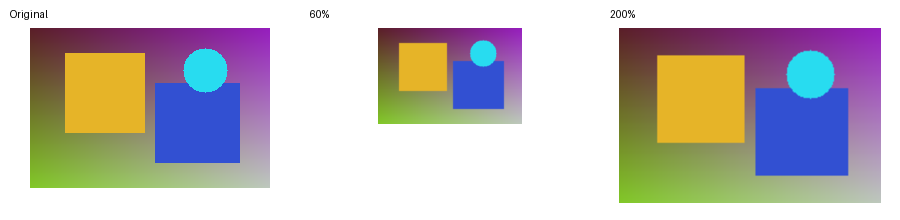

In [2]:
# Task 2: resize while preserving the original aspect ratio.
downscaled = cv.resize(image_bgr, None, fx=0.60, fy=0.60, interpolation=cv.INTER_AREA)
upscaled = cv.resize(image_bgr, None, fx=2.00, fy=2.00, interpolation=cv.INTER_LINEAR)
print(f"Original: {image_bgr.shape}; 60%: {downscaled.shape}; 200%: {upscaled.shape}")
show_images([("Original", image_bgr), ("60%", downscaled), ("200%", upscaled)], "task02_aspect_ratio", cols=3)


### Task 3: Resize Without Preserving Aspect Ratio
Resize only width to 100 pixels, only height to 200 pixels, and both to (200, 200). Display and discuss distortions.

Width only: (160, 100, 3); height only: (200, 240, 3); square: (200, 200, 3)
Changing one dimension independently alters the aspect ratio; forcing both dimensions to 200 can distort both axes.
task03_distorted_resize: tasks1_outputs\task03_distorted_resize.png


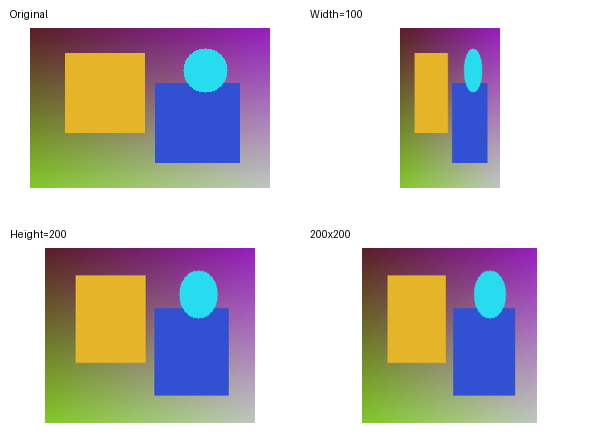

In [3]:
# Task 3: resize without preserving aspect ratio.
width_only = cv.resize(image_bgr, (100, image_bgr.shape[0]), interpolation=cv.INTER_LINEAR)
height_only = cv.resize(image_bgr, (image_bgr.shape[1], 200), interpolation=cv.INTER_LINEAR)
fixed_square = cv.resize(image_bgr, (200, 200), interpolation=cv.INTER_LINEAR)
print(f"Width only: {width_only.shape}; height only: {height_only.shape}; square: {fixed_square.shape}")
print("Changing one dimension independently alters the aspect ratio; forcing both dimensions to 200 can distort both axes.")
show_images([("Original", image_bgr), ("Width=100", width_only), ("Height=200", height_only), ("200x200", fixed_square)], "task03_distorted_resize", cols=2)


### Task 4: Resize Using Scale Factors (fx, fy)
Scale up by 1.2 in both directions and down by 0.6. Use different interpolations (INTER_LINEAR, INTER_NEAREST) and compare quality.

1.2x linear=(192, 288, 3), nearest=(192, 288, 3); 0.6x linear=(96, 144, 3), nearest=(96, 144, 3)
task04_interpolation: tasks1_outputs\task04_interpolation.png


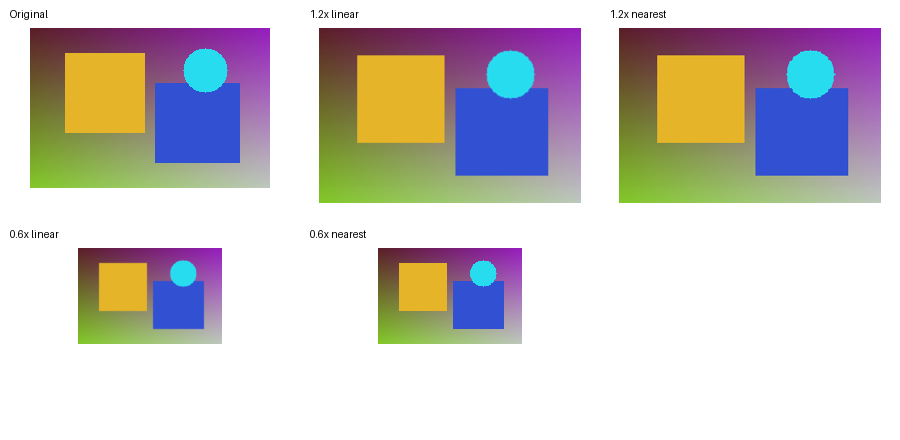

In [4]:
# Task 4: scale with fx/fy and compare interpolation methods.
linear_up = cv.resize(image_bgr, None, fx=1.2, fy=1.2, interpolation=cv.INTER_LINEAR)
nearest_up = cv.resize(image_bgr, None, fx=1.2, fy=1.2, interpolation=cv.INTER_NEAREST)
linear_down = cv.resize(image_bgr, None, fx=0.6, fy=0.6, interpolation=cv.INTER_LINEAR)
nearest_down = cv.resize(image_bgr, None, fx=0.6, fy=0.6, interpolation=cv.INTER_NEAREST)
print(f"1.2x linear={linear_up.shape}, nearest={nearest_up.shape}; 0.6x linear={linear_down.shape}, nearest={nearest_down.shape}")
show_images([("Original", image_bgr), ("1.2x linear", linear_up), ("1.2x nearest", nearest_up), ("0.6x linear", linear_down), ("0.6x nearest", nearest_down)], "task04_interpolation", cols=3)


### Task 5: Cropping an Image
Crop a region (e.g., [20:200, 50:200]) from the image. Display original and cropped.

Crop [20:160, 50:200] -> (140, 150, 3)
task05_crop: tasks1_outputs\task05_crop.png


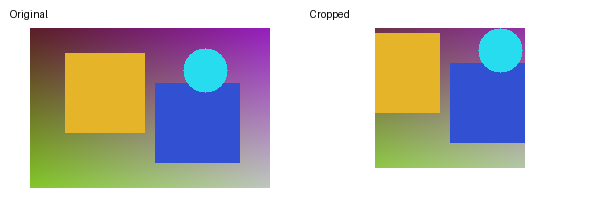

In [5]:
# Task 5: crop the requested region and compare it with the source.
y1, y2 = 20, min(200, image_bgr.shape[0])
x1, x2 = 50, min(200, image_bgr.shape[1])
cropped = image_bgr[y1:y2, x1:x2]
print(f"Crop [{y1}:{y2}, {x1}:{x2}] -> {cropped.shape}")
show_images([("Original", image_bgr), ("Cropped", cropped)], "task05_crop", cols=2)


### Task 6: Advanced Cropping - Patch Image into Blocks
Divide the image into 4 equal blocks (2x2 grid) by cropping. Display each block separately and then stitch them back using NumPy concatenation to verify.

Blocks: (80, 120, 3), (80, 120, 3), (80, 120, 3), (80, 120, 3)
Stitch matches original: True
task06_blocks: tasks1_outputs\task06_blocks.png


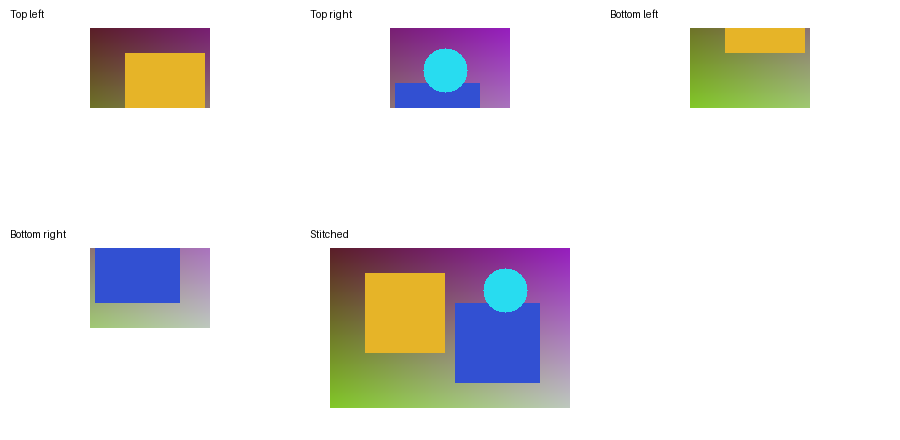

In [6]:
# Task 6: split into a 2x2 grid and stitch the blocks back together.
height, width = image_bgr.shape[:2]
mid_y, mid_x = height // 2, width // 2
top_left = image_bgr[:mid_y, :mid_x]
top_right = image_bgr[:mid_y, mid_x:]
bottom_left = image_bgr[mid_y:, :mid_x]
bottom_right = image_bgr[mid_y:, mid_x:]
top = np.hstack((top_left, top_right))
bottom = np.hstack((bottom_left, bottom_right))
stitched = np.vstack((top, bottom))
print(f"Blocks: {top_left.shape}, {top_right.shape}, {bottom_left.shape}, {bottom_right.shape}")
print(f"Stitch matches original: {np.array_equal(stitched, image_bgr)}")
show_images([("Top left", top_left), ("Top right", top_right), ("Bottom left", bottom_left), ("Bottom right", bottom_right), ("Stitched", stitched)], "task06_blocks", cols=3)


### Task 7: Rotating an Image
Rotate the image by 45°, 90°, and 180° using getRotationMatrix2D and warpAffine. Display all rotations.

task07_rotations: tasks1_outputs\task07_rotations.png


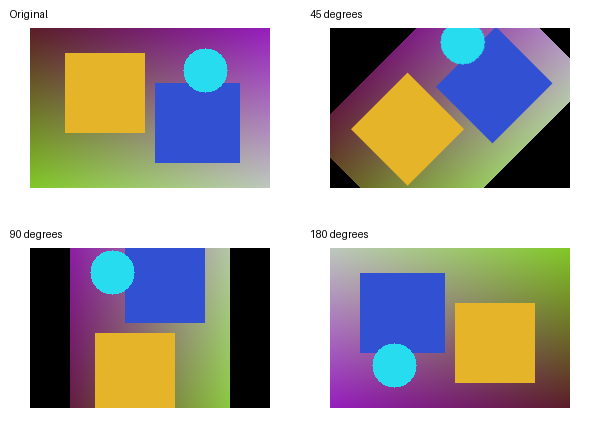

In [7]:
# Task 7: rotate with an affine matrix while retaining the original canvas size.
center = (image_bgr.shape[1] / 2.0, image_bgr.shape[0] / 2.0)
rotations = []
for angle in (45, 90, 180):
    matrix = cv.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv.warpAffine(image_bgr, matrix, (image_bgr.shape[1], image_bgr.shape[0]))
    rotations.append((f"{angle} degrees", rotated))
show_images([("Original", image_bgr)] + rotations, "task07_rotations", cols=2)


### Task 8: Rotate with Scaling
Rotate by 45° and scale by 0.5 in **one** operation. Compare with separate resize and rotate.

One operation: (160, 240, 3); separate operations: (80, 120, 3)
task08_rotate_scale: tasks1_outputs\task08_rotate_scale.png


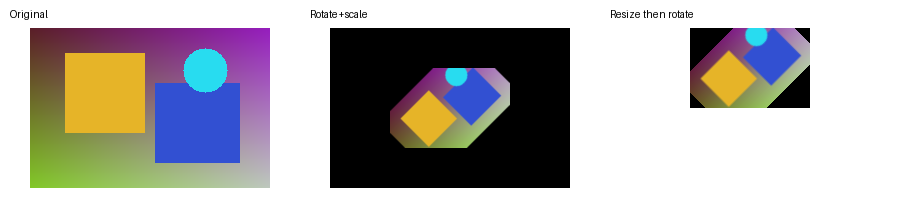

In [8]:
# Task 8: rotate and scale in one affine operation, then compare with separate operations.
matrix = cv.getRotationMatrix2D(center, 45, 0.5)
one_operation = cv.warpAffine(image_bgr, matrix, (image_bgr.shape[1], image_bgr.shape[0]))
half_size = cv.resize(image_bgr, None, fx=0.5, fy=0.5, interpolation=cv.INTER_AREA)
small_center = (half_size.shape[1] / 2.0, half_size.shape[0] / 2.0)
separate_matrix = cv.getRotationMatrix2D(small_center, 45, 1.0)
separate_operations = cv.warpAffine(half_size, separate_matrix, (half_size.shape[1], half_size.shape[0]))
print(f"One operation: {one_operation.shape}; separate operations: {separate_operations.shape}")
show_images([("Original", image_bgr), ("Rotate+scale", one_operation), ("Resize then rotate", separate_operations)], "task08_rotate_scale", cols=3)


## Session 2: Image Acquisition, Formats, Color Spaces, Enhancement, and Filtering

### Task 9: Read Image in Different Color Spaces
Read an image in BGR, convert to RGB (for Matplotlib), HSV, LAB and Grayscale. Display all.

task09_color_spaces: tasks1_outputs\task09_color_spaces.png
Color shapes: BGR=(160, 240, 3), RGB=(160, 240, 3), HSV=(160, 240, 3), LAB=(160, 240, 3), gray=(160, 240)


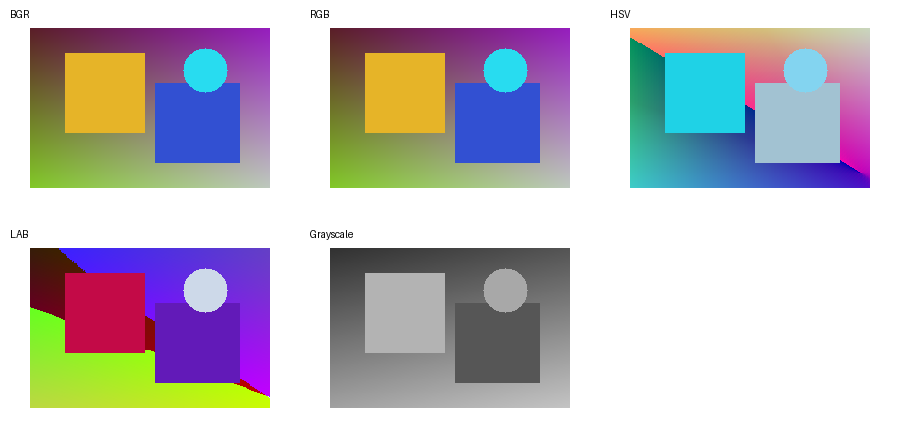

In [9]:
# Task 9: inspect BGR, RGB, HSV, LAB and grayscale representations.
image_rgb = cv.cvtColor(image_bgr, cv.COLOR_BGR2RGB)
image_hsv = cv.cvtColor(image_bgr, cv.COLOR_BGR2HSV)
image_lab = cv.cvtColor(image_bgr, cv.COLOR_BGR2LAB)
show_images([("BGR", image_bgr), ("RGB", image_rgb, "rgb"), ("HSV", image_hsv, "raw"), ("LAB", image_lab, "raw"), ("Grayscale", image_gray)], "task09_color_spaces", cols=3)
print(f"Color shapes: BGR={image_bgr.shape}, RGB={image_rgb.shape}, HSV={image_hsv.shape}, LAB={image_lab.shape}, gray={image_gray.shape}")


### Task 10: Image Sharpening
Apply cv2.blur() with a 5x5 kernel, then use cv2.filter2D() with sharpening kernels of varying strengths (e.g., [[0, -1, 0], [-1, 5, -1], [0, -1, 0]] and [[0, -2, 0], [-2, 9, -2], [0, -2, 0]]).
Compare between original and sharpened image after blurring.

task10_sharpening: tasks1_outputs\task10_sharpening.png


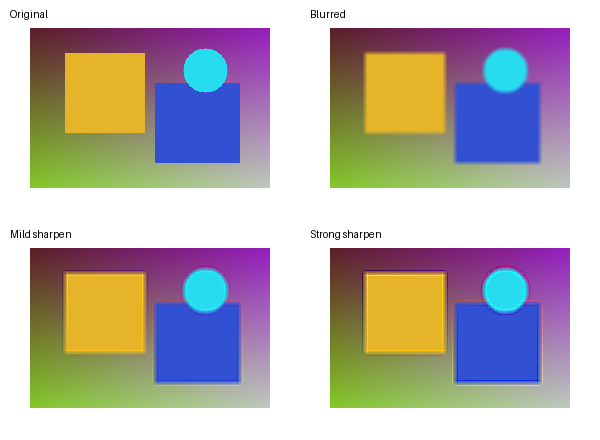

In [10]:
# Task 10: blur first, then sharpen with two kernel strengths.
blurred = cv.blur(image_bgr, (5, 5))
kernel_mild = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
kernel_strong = np.array([[0, -2, 0], [-2, 9, -2], [0, -2, 0]], dtype=np.float32)
sharpened_mild = cv.filter2D(blurred, -1, kernel_mild)
sharpened_strong = cv.filter2D(blurred, -1, kernel_strong)
show_images([("Original", image_bgr), ("Blurred", blurred), ("Mild sharpen", sharpened_mild), ("Strong sharpen", sharpened_strong)], "task10_sharpening", cols=2)


### Task 11: Add Salt and Pepper Noise to Image
Implement a function to add salt and pepper noise to an image. Control noise density (e.g., 0.05).

Noise density=0.05; altered grayscale pixels=1881
task11_salt_pepper: tasks1_outputs\task11_salt_pepper.png


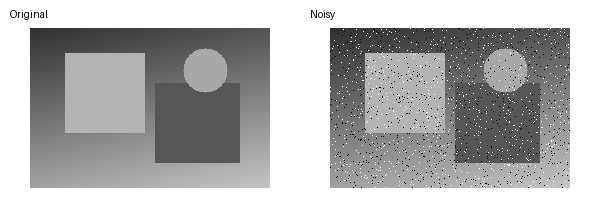

In [11]:
# Task 11: add deterministic salt-and-pepper noise to grayscale or color images.
def add_salt_pepper_noise(image, density=0.05, seed=42):
    if not 0 <= density <= 1:
        raise ValueError("density must be between 0 and 1")
    noisy = np.array(image, copy=True)
    rng = np.random.default_rng(seed)
    count = int(round(density * noisy.shape[0] * noisy.shape[1]))
    rows = rng.integers(0, noisy.shape[0], count)
    cols = rng.integers(0, noisy.shape[1], count)
    half = count // 2
    if noisy.ndim == 2:
        noisy[rows[:half], cols[:half]] = 0
        noisy[rows[half:], cols[half:]] = 255
    else:
        noisy[rows[:half], cols[:half], :] = 0
        noisy[rows[half:], cols[half:], :] = 255
    return noisy

noisy_gray = add_salt_pepper_noise(image_gray, density=0.05)
noisy_color = add_salt_pepper_noise(image_bgr, density=0.05)
print(f"Noise density=0.05; altered grayscale pixels={np.count_nonzero(noisy_gray != image_gray)}")
show_images([("Original", image_gray), ("Noisy", noisy_gray)], "task11_salt_pepper", cols=2)


### Task 12: Remove Salt and Pepper Noise Using Median Filter
Apply cv.medianBlur() to a noisy image. Experiment with kernel sizes (3,5,7) and compare results.

task12_median_filter: tasks1_outputs\task12_median_filter.png


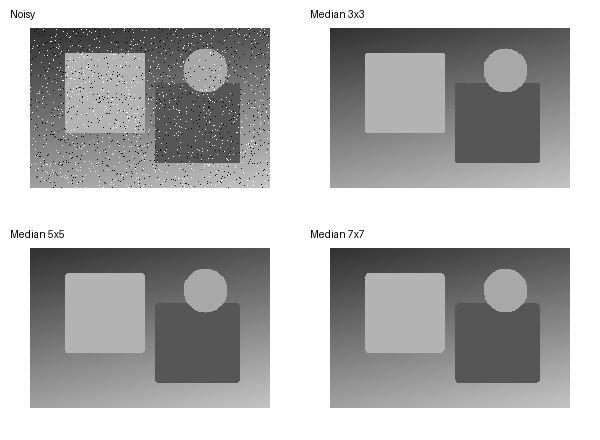

In [12]:
# Task 12: compare median filters with three window sizes.
median_3 = cv.medianBlur(noisy_gray, 3)
median_5 = cv.medianBlur(noisy_gray, 5)
median_7 = cv.medianBlur(noisy_gray, 7)
show_images([("Noisy", noisy_gray), ("Median 3x3", median_3), ("Median 5x5", median_5), ("Median 7x7", median_7)], "task12_median_filter", cols=2)


### Task 13: Implement Adaptive Median Filter
Write a custom function for adaptive median filtering. It should dynamically increase window size until noise is removed or max size is reached. Apply to a noisy image and compare with standard median.

task13_adaptive_median: tasks1_outputs\task13_adaptive_median.png


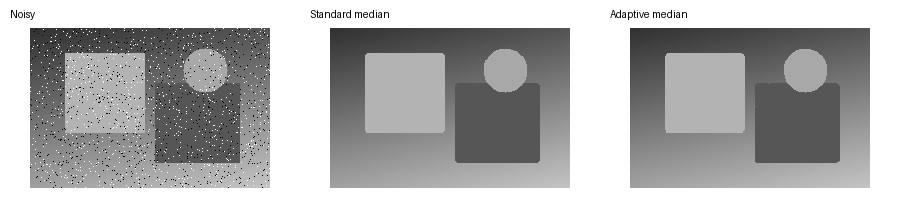

In [13]:
# Task 13: adaptive median filtering with a growing odd-sized window.
def adaptive_median_filter(image, max_size=7):
    if max_size < 3 or max_size % 2 == 0:
        raise ValueError("max_size must be an odd integer >= 3")
    source = np.asarray(image)
    if source.ndim != 2:
        raise ValueError("adaptive_median_filter expects a grayscale image")
    radius = max_size // 2
    padded = np.pad(source, radius, mode="reflect")
    result = np.empty_like(source)
    for row in range(source.shape[0]):
        for col in range(source.shape[1]):
            value = source[row, col]
            chosen = value
            size = 3
            while size <= max_size:
                half = size // 2
                window = padded[row + radius - half:row + radius + half + 1, col + radius - half:col + radius + half + 1]
                z_min, z_max = window.min(), window.max()
                z_med = np.median(window)
                if z_min < z_med < z_max:
                    chosen = value if z_min < value < z_max else z_med
                    break
                size += 2
            else:
                half = max_size // 2
                chosen = np.median(padded[row + radius - half:row + radius + half + 1, col + radius - half:col + radius + half + 1])
            result[row, col] = chosen
    return result.astype(source.dtype)

adaptive = adaptive_median_filter(noisy_gray, max_size=7)
show_images([("Noisy", noisy_gray), ("Standard median", median_5), ("Adaptive median", adaptive)], "task13_adaptive_median", cols=3)


### Task 14: Implement Bilateral Filter Function
Write a Python function to perform bilateral filtering on an image. Use Gaussian weights for both spatial and intensity. Parameters: diameter, sigma_color, sigma_space. Compare with cv.bilateralFilter().

Mean absolute difference from cv.bilateralFilter: 0.00
task14_bilateral: tasks1_outputs\task14_bilateral.png


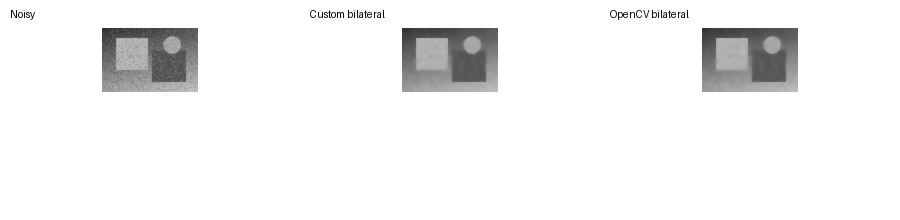

In [14]:
# Task 14: bilateral filter using spatial and intensity Gaussian weights.
def custom_bilateral_filter(image, diameter, sigma_color, sigma_space):
    if diameter < 3 or diameter % 2 == 0:
        raise ValueError("diameter must be an odd integer >= 3")
    source = np.asarray(image)
    original_ndim = source.ndim
    if original_ndim == 2:
        source_work = source[..., None]
    elif original_ndim == 3:
        source_work = source
    else:
        raise ValueError("image must be grayscale or BGR")
    radius = diameter // 2
    padded = np.pad(source_work.astype(np.float32), ((radius, radius), (radius, radius), (0, 0)), mode="reflect")
    yy, xx = np.mgrid[-radius:radius + 1, -radius:radius + 1]
    spatial = np.exp(-(xx * xx + yy * yy) / (2 * sigma_space * sigma_space))
    result = np.empty_like(source_work, dtype=np.float32)
    color_denominator = 2 * sigma_color * sigma_color
    for row in range(source.shape[0]):
        for col in range(source.shape[1]):
            center = padded[row + radius, col + radius]
            window = padded[row:row + diameter, col:col + diameter]
            difference = window - center
            intensity_distance = np.sum(difference * difference, axis=-1)
            intensity_weights = np.exp(-intensity_distance / color_denominator)
            weights = spatial * intensity_weights
            result[row, col] = np.sum(window * weights[..., None], axis=(0, 1)) / max(weights.sum(), 1e-12)
    result = np.clip(result, 0, 255).astype(source.dtype)
    return result[..., 0] if original_ndim == 2 else result

small_noisy = cv.resize(noisy_gray, (96, 64), interpolation=cv.INTER_AREA)
custom_bilateral = custom_bilateral_filter(small_noisy, diameter=5, sigma_color=35, sigma_space=35)
opencv_bilateral = cv.bilateralFilter(small_noisy, 5, 35, 35)
mean_absolute_difference = np.mean(np.abs(custom_bilateral.astype(np.float32) - opencv_bilateral.astype(np.float32)))
print(f"Mean absolute difference from cv.bilateralFilter: {mean_absolute_difference:.2f}")
show_images([("Noisy", small_noisy), ("Custom bilateral", custom_bilateral), ("OpenCV bilateral", opencv_bilateral)], "task14_bilateral", cols=3)


### [BONUS] Task 15: Comprehensive Camera Task 
Combine: Live camera feed -> grayscale -> add noise -> remove with median -> sharpen. Display all stages in separate windows.

No camera available; demonstrated the full pipeline with the reproducible sample image.
task15_camera_pipeline: tasks1_outputs\task15_camera_pipeline.png


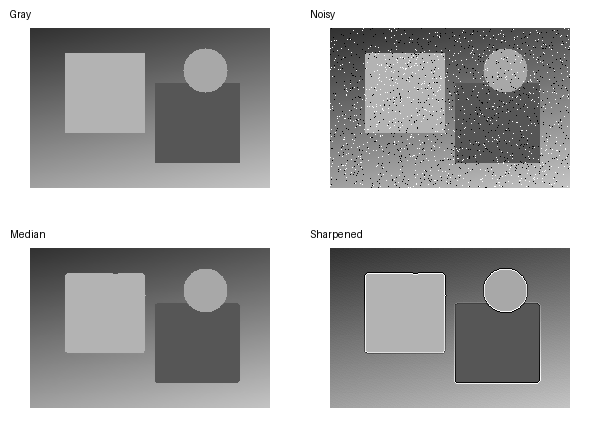

In [15]:
# Bonus Task 15: camera pipeline. The sample image is used when no camera is available.
def process_frame(frame):
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    noisy = add_salt_pepper_noise(gray, density=0.05, seed=7)
    denoised = cv.medianBlur(noisy, 5)
    sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
    sharpened = cv.filter2D(denoised, -1, sharpen_kernel)
    return gray, noisy, denoised, sharpened

camera_id = 0
cap = cv.VideoCapture(camera_id)
if cap.isOpened():
    ret, frame = cap.read()
    cap.release()
    if ret:
        stages = process_frame(frame)
        show_images(list(zip(("Gray", "Noisy", "Median", "Sharpened"), stages)), "task15_camera_pipeline", cols=2)
    else:
        print("Camera opened but returned no frame.")
else:
    cap.release()
    stages = process_frame(image_bgr)
    print("No camera available; demonstrated the full pipeline with the reproducible sample image.")
    show_images(list(zip(("Gray", "Noisy", "Median", "Sharpened"), stages)), "task15_camera_pipeline", cols=2)


### [BONUS]Task 16: Comprehensive Video Task
Similar to Task 18 but for a video file. Save the final processed video.

In [16]:
# Bonus Task 16: process a video file and save the final processed video.
def process_video_file(input_path, output_path):
    capture = cv.VideoCapture(str(input_path))
    if not capture.isOpened():
        return False
    fps = capture.get(getattr(cv, "CAP_PROP_FPS", 5)) or 20.0
    width = int(capture.get(getattr(cv, "CAP_PROP_FRAME_WIDTH", 3)))
    height = int(capture.get(getattr(cv, "CAP_PROP_FRAME_HEIGHT", 4)))
    writer = cv.VideoWriter(str(output_path), getattr(cv, "VideoWriter_fourcc", lambda *args: 0)(*"mp4v"), fps, (width, height), False)
    if not writer.isOpened():
        capture.release()
        return False
    while True:
        ret, frame = capture.read()
        if not ret:
            break
        gray, noisy, denoised, sharpened = process_frame(frame)
        writer.write(sharpened)
    capture.release()
    writer.release()
    return True

video_input = Path("input_video.mp4")
video_output = ARTIFACT_DIR / "processed_video.mp4"
if video_input.exists() and process_video_file(video_input, video_output):
    print(f"Processed video saved to {video_output}")
else:
    print("No input_video.mp4 was supplied; video processing function is implemented and ready for a video file.")


No input_video.mp4 was supplied; video processing function is implemented and ready for a video file.


### Task 17: Performance Comparison
Time the execution of standard median vs adaptive median on a large noisy image. Discuss when adaptive median filter is better.

In [17]:
# Task 17: compare standard median and adaptive median timing.
benchmark_source = cv.resize(noisy_gray, (160, 120), interpolation=cv.INTER_AREA)
start = time.perf_counter()
_ = cv.medianBlur(benchmark_source, 5)
standard_seconds = time.perf_counter() - start
start = time.perf_counter()
_ = adaptive_median_filter(benchmark_source, max_size=5)
adaptive_seconds = time.perf_counter() - start
print(f"Benchmark image: {benchmark_source.shape}")
print(f"Standard median: {standard_seconds:.4f} seconds")
print(f"Adaptive median: {adaptive_seconds:.4f} seconds")
print("Adaptive median is useful when noise density varies or isolated impulses should be treated while preserving edges; standard median is usually faster for uniform noise.")


Benchmark image: (120, 160)
Standard median: 0.0033 seconds
Adaptive median: 0.2382 seconds
Adaptive median is useful when noise density varies or isolated impulses should be treated while preserving edges; standard median is usually faster for uniform noise.
